In [49]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Weak scaling Plots

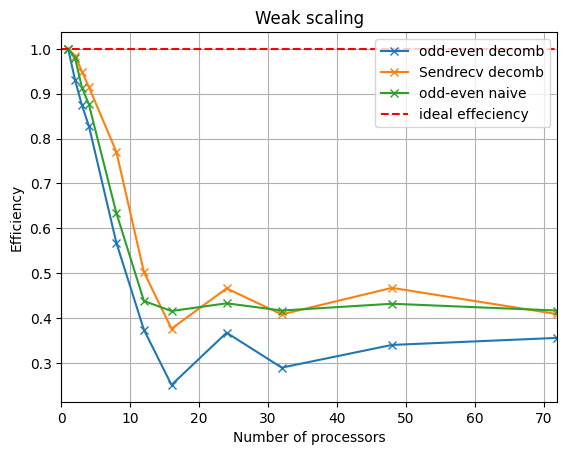

In [50]:
# Load data
decomb_sendrecv_laura = pd.read_csv("results/speedup/weak_scaling_decomb_implementation_sendrecv.csv")
decomb_Sendrecv = pd.read_csv("results/speedup/weak_scaling_decomb_implementation.csv")
sendrecv = pd.read_csv("results/speedup/weak_scaling_sendrecv_implementation.csv")

data = [decomb_sendrecv_laura, decomb_Sendrecv, sendrecv]
names = ["odd-even decomb", "Sendrecv decomb", "odd-even naive"]

for i in range(3):
    df = data[i]
    name = names[i]

    column = "total_time"

    group = df.groupby("n_ranks").max()
    group["total_time"] = group["jacobi_time"] + group["comm_time"]

    efficiency = group[column][1] / group[column]
    plt.plot(group.index, efficiency,"-x", label=name)

plt.hlines(1, 0, 75, linestyles="--", color="red", label="ideal effeciency")
plt.xlim(0,72)
plt.xlabel("Number of processors")
plt.ylabel("Efficiency")
plt.title("Weak scaling")
plt.legend()
plt.grid()
plt.show()

# Strong scaling 

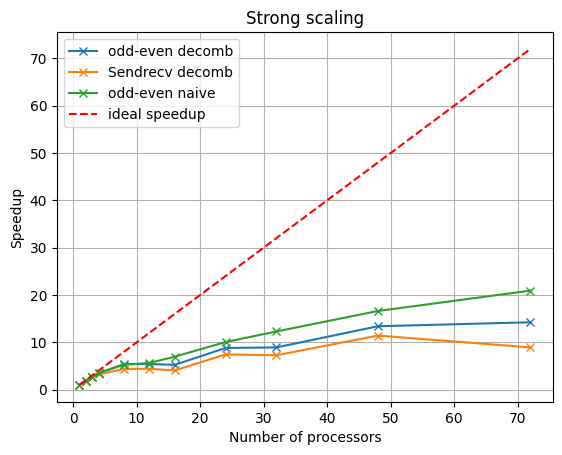

In [56]:
df = pd.read_csv("results/speedup/strong_scaling.csv")
baslinevalue = 0
names = ["odd-even decomb", "Sendrecv decomb", "odd-even naive"]
i = 0
for type, data in df.groupby("type"):

    group = data.groupby("n_ranks").max()
    group["total_time"] = group["jacobi_time"] + group["comm_time"]
    baslinevalue = group["total_time"][1]
    speedup = group["total_time"][1] / group["total_time"]

    plt.plot(group.index, speedup,"-x", label=f"{names[i]}")
    i += 1



plt.xlabel("Number of processors")
plt.ylabel("Speedup")
plt.title("Strong scaling")
n_procs = np.arange(1, 73)
plt.plot(n_procs, n_procs, "--", color="red", label="ideal speedup")
plt.grid()
plt.legend()